In [2]:
%pip install seaborn
#sns インストール

Note: you may need to restart the kernel to use updated packages.


In [3]:
import pandas as pd
import numpy as np
from matplotlib import pyplot as plt
import seaborn as sns
#ライブラリをインポート

In [4]:
train = pd.read_csv('train.csv') # 学習データの読み込み
test = pd.read_csv('test.csv') # 検証データの読み込み
sample = pd.read_csv('sample.csv', header=None) # 提出用サンプルデータの読み込み

# データ確認
train.head()

,datetime,y,week,soldout,name,kcal,remarks,event,payday,weather,precipitation,temperature
0,2013-11-18,90,月,0,厚切りイカフライ,NaN,NaN,NaN,NaN,快晴,--,19.8
1,2013-11-19,101,火,1,手作りヒレカツ,NaN,NaN,NaN,NaN,快晴,--,17.0
2,2013-11-20,118,水,0,白身魚唐揚げ野菜あん,NaN,NaN,NaN,NaN,快晴,--,15.5
3,2013-11-21,120,木,1,若鶏ピリ辛焼,NaN,NaN,NaN,NaN,快晴,--,15.2
4,2013-11-22,130,金,1,ビッグメンチカツ,NaN,NaN,NaN,NaN,快晴,--,16.1


In [5]:
test.head()

,datetime,week,soldout,name,kcal,remarks,event,payday,weather,precipitation,temperature
0,2014-10-1,水,1,メンチカツ,420.0,NaN,NaN,NaN,雨,0,20.2
1,2014-10-2,木,0,バーベキューチキン,415.0,NaN,NaN,NaN,曇,--,23.9
2,2014-10-3,金,0,豚肉のマスタード焼き,405.0,NaN,NaN,NaN,晴れ,--,28.7
3,2014-10-6,月,1,麻婆春雨,400.0,NaN,NaN,NaN,雨,0.5,21.5
4,2014-10-7,火,0,厚揚げ肉みそ炒め,430.0,NaN,NaN,NaN,晴れ,--,22.1


In [6]:
# フラグを立てる
train['flg'] = 1
test['flg'] = 0
# trainデータとtestデータを結合
all_data = pd.concat([train,test], axis=0, sort=False)

In [7]:
# 欠損数、型確認
all_data.info()

<class 'pandas.DataFrame'>
Index: 247 entries, 0 to 39
Data columns (total 13 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   datetime       247 non-null    str    
 1   y              207 non-null    float64
 2   week           247 non-null    str    
 3   soldout        247 non-null    int64  
 4   name           247 non-null    str    
 5   kcal           202 non-null    float64
 6   remarks        28 non-null     str    
 7   event          17 non-null     str    
 8   payday         12 non-null     float64
 9   weather        247 non-null    str    
 10  precipitation  247 non-null    str    
 11  temperature    247 non-null    float64
 12  flg            247 non-null    int64  
dtypes: float64(4), int64(2), str(7)
memory usage: 27.0 KB


In [8]:
train.isnull().sum()
#Nullの数を調べる

datetime           0
y                  0
week               0
soldout            0
name               0
kcal              41
remarks          186
event            193
payday           197
weather            0
precipitation      0
temperature        0
flg                0
dtype: int64

In [9]:
all_data['kcal'] = all_data['kcal'].fillna(train['kcal'].mean())
all_data['kcal'].head()
#カロリーの欠損地を平均値で補完 

0    404.409639
1    404.409639
2    404.409639
3    404.409639
4    404.409639
Name: kcal, dtype: float64

In [10]:
print(train.payday.unique())
all_data.loc[~all_data['payday'].isnull() , ['week', 'payday']]
#Paydayの有無を確認する

[nan  1.]


,week,payday
16,火,1.0
31,金,1.0
51,月,1.0
70,月,1.0
92,木,1.0
110,金,1.0
132,火,1.0
154,木,1.0
174,金,1.0
194,水,1.0


In [11]:
all_data['payday'] = all_data['payday'].fillna(0)
all_data['payday'].unique()
#paydayの欠損値を0で補完する

array([0., 1.])

In [12]:
#降水量の前処理
# 降水量が--の時
all_data[all_data['precipitation'] == "--"]['weather'].unique()

<StringArray>
['快晴', '曇', '晴れ', '薄曇']
Length: 4, dtype: str

In [13]:
# 降水量が0の時
all_data[all_data['precipitation'] == "0"]['weather'].unique()

<StringArray>
['雨', '曇', '雷電', '薄曇']
Length: 4, dtype: str

In [14]:
# 降水量に数値が入っている時
all_data[~(all_data['precipitation'] == '0') & ~(all_data['precipitation'] == '--')]['weather'].unique()

<StringArray>
['曇', '雨', '雪']
Length: 3, dtype: str

In [15]:
# precipitation_flg(カテゴリ変数)
all_data['precipitation_flg'] = '悪い'
all_data.loc[(all_data['precipitation'] == '--'), 'precipitation_flg'] = '良い'
all_data.loc[(all_data['precipitation'] == '0'), 'precipitation_flg'] = 'やや悪い'

In [16]:
# 文字列を数値データに変える(量的変数)
all_data['precipitation'] = all_data['precipitation'].replace('--', '-1')

In [2]:
#データの概要を知る
train.describe()

NameError: name 'train' is not defined

<Axes: >

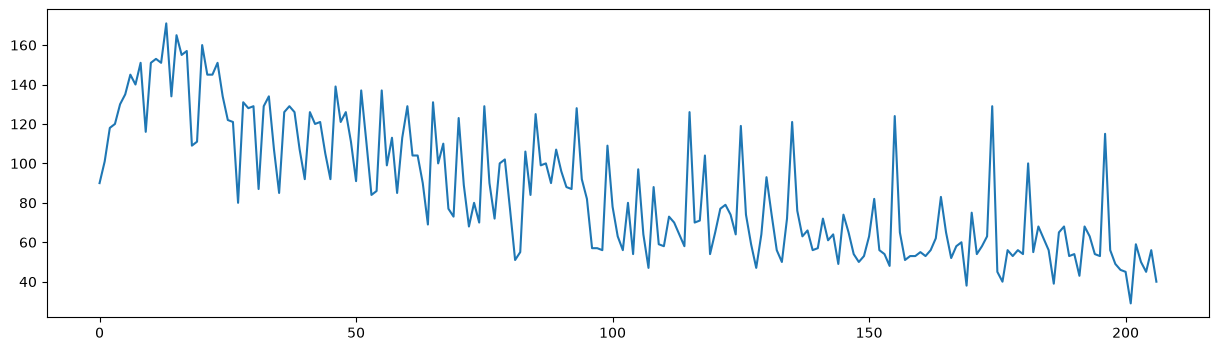

In [18]:
train["y"].plot(figsize=(15,4))
#売上のグラフ化

C:\Users\NDY13\AppData\Local\Temp\ipykernel_9268\1246012862.py:5: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax[1][0].set_xticklabels(ax[1][0].get_xticklabels(),rotation=30)
C:\Users\NDY13\AppData\Local\Temp\ipykernel_9268\1246012862.py:7: UserWarning: Glyph 26376 (\N{CJK UNIFIED IDEOGRAPH-6708}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\NDY13\AppData\Local\Temp\ipykernel_9268\1246012862.py:7: UserWarning: Glyph 28779 (\N{CJK UNIFIED IDEOGRAPH-706B}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\NDY13\AppData\Local\Temp\ipykernel_9268\1246012862.py:7: UserWarning: Glyph 27700 (\N{CJK UNIFIED IDEOGRAPH-6C34}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\NDY13\AppData\Local\Temp\ipykernel_9268\1246012862.py:7: UserWarning: Glyph 26408 (\N{CJK UNIFIED IDEOGRAPH-6728}) missing from font(s) DejaVu Sans.
  plt.ti

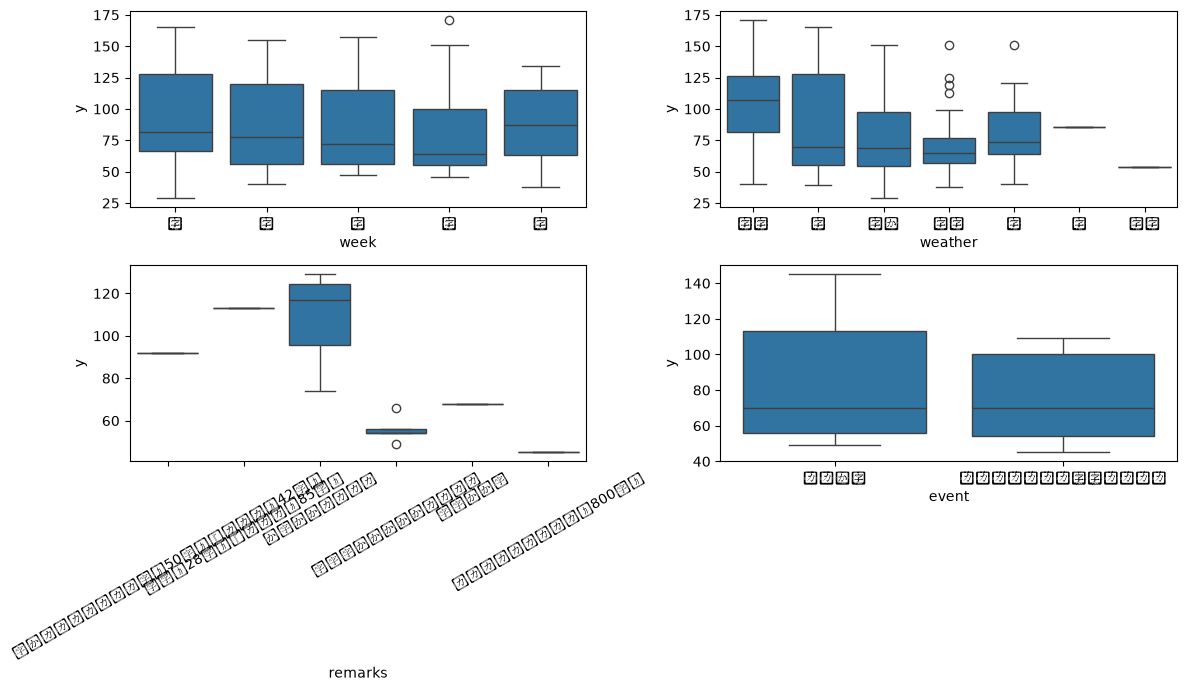

In [19]:
fig, ax = plt.subplots(2,2,figsize=(12,7))
sns.boxplot(x="week",y="y",data=train,ax=ax[0][0])
sns.boxplot(x="weather",y="y",data=train,ax=ax[0][1])
sns.boxplot(x="remarks",y="y",data=train,ax=ax[1][0])
ax[1][0].set_xticklabels(ax[1][0].get_xticklabels(),rotation=30)
sns.boxplot(x="event",y="y",data=train,ax=ax[1][1])
plt.tight_layout()
#グラフ化して、売上に影響を与える要素を確認する

In [20]:
all_data.loc[all_data['remarks'] != 'お楽しみメニュー', 'remarks'] = 'なし'
all_data['remarks'].unique()
#お楽しみメニューの有無を確認する
#欠損値を「なし」で補完する

<StringArray>
['なし', 'お楽しみメニュー']
Length: 2, dtype: str

In [21]:
all_data['event'] = all_data['event'].fillna('なし')
all_data['event'].unique()
#eventの欠損値を「なし」で補完する

<StringArray>
['なし', 'ママの会', 'キャリアアップ支援セミナー']
Length: 3, dtype: str

In [22]:
all_data.info()
#欠損値がなくなったことを確認する

<class 'pandas.DataFrame'>
Index: 247 entries, 0 to 39
Data columns (total 14 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   datetime           247 non-null    str    
 1   y                  207 non-null    float64
 2   week               247 non-null    str    
 3   soldout            247 non-null    int64  
 4   name               247 non-null    str    
 5   kcal               247 non-null    float64
 6   remarks            247 non-null    str    
 7   event              247 non-null    str    
 8   payday             247 non-null    float64
 9   weather            247 non-null    str    
 10  precipitation      247 non-null    str    
 11  temperature        247 non-null    float64
 12  flg                247 non-null    int64  
 13  precipitation_flg  247 non-null    str    
dtypes: float64(4), int64(2), str(8)
memory usage: 28.9 KB


In [23]:
# 経過日数カラムを作成
all_data['days'] = range(1,len(all_data)+1)

In [24]:
# 各カラムの一意の値を見る
for col in all_data.columns:
    print(col,all_data[col].unique())
    print(all_data[col].nunique())
    print('----------------------------------------------')

datetime <StringArray>
['2013-11-18', '2013-11-19', '2013-11-20', '2013-11-21', '2013-11-22',
 '2013-11-25', '2013-11-26', '2013-11-27', '2013-11-28', '2013-11-29',
 ...
 '2014-11-14', '2014-11-17', '2014-11-18', '2014-11-19', '2014-11-20',
 '2014-11-21', '2014-11-25', '2014-11-26', '2014-11-27', '2014-11-28']
Length: 247, dtype: str
247
----------------------------------------------
y [ 90. 101. 118. 120. 130. 135. 145. 140. 151. 116. 153. 171. 134. 165.
 155. 157. 109. 111. 160. 122. 121.  80. 131. 128. 129.  87. 107.  85.
 126.  92. 105. 139.  91. 137.  84.  86.  99. 113. 104.  69. 100. 110.
  77.  73. 123.  89.  68.  70.  72. 102.  51.  55. 106. 125.  96.  88.
  82.  57.  56.  78.  63.  54.  97.  64.  47.  59.  58.  71.  65.  79.
  74. 119.  93.  50.  76.  66.  61.  49.  53.  48. 124.  62.  83.  52.
  60.  38.  75.  45.  40.  39.  43. 115.  46.  29.  nan]
94
----------------------------------------------
week <StringArray>
['月', '火', '水', '木', '金']
Length: 5, dtype: str
5
---------

In [25]:
# One-Hotエンコーダー
ohe_columns = ['week','soldout','remarks','event','payday','weather','precipitation_flg']

all_data = pd.get_dummies(all_data, dummy_na=False, columns=ohe_columns)

In [26]:
all_data[['week_月','week_火','week_水','week_木','week_金',]].head(10)

,week_月,week_火,week_水,week_木,week_金
0,True,False,False,False,False
1,False,True,False,False,False
2,False,False,True,False,False
3,False,False,False,True,False
4,False,False,False,False,True
5,True,False,False,False,False
6,False,True,False,False,False
7,False,False,True,False,False
8,False,False,False,True,False
9,False,False,False,False,True


In [27]:
# trainとtestにわける
train = all_data.query('flg == 1')
test = all_data.query('flg == 0')

In [28]:
train.drop(['flg','name'], axis=1,inplace=True)
test.drop(['flg','name','y'], axis=1,inplace=True)
#不要なカラムを削除する

In [29]:
# trainデータの説明変数と目的変数をわける
linear_X_train = train[["days", "temperature", "kcal", "remarks_お楽しみメニュー", "remarks_なし"
                       ,"week_月", "week_火", "week_水", "week_木", "week_金", "weather_雨","soldout_1"
                      ,"precipitation_flg_やや悪い","precipitation_flg_悪い"]]

# 目的変数はLinear,RandomForest共通
y_train = train['y']

# testデータもlinear_X_trainと同じカラムにする
linear_test = test[["days", "temperature", "kcal", "remarks_お楽しみメニュー", "remarks_なし"
                 ,"week_月", "week_火", "week_水", "week_木", "week_金", "weather_雨","soldout_1"
                ,"precipitation_flg_やや悪い","precipitation_flg_悪い"]]

In [30]:
%pip install Cython
import sklearn
sklearn.set_config(display="text")
%pip install scikit-learn
from sklearn.linear_model import LinearRegression as LR 
%matplotlib inline 
# 線形回帰のモデルインポート

Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.


In [31]:
# LinearRegressionのパラメータ設定
linear = LR()

In [32]:
# 線形回帰モデル作成
linear.fit(linear_X_train,y_train)

# 予測
Linear_pred = linear.predict(linear_X_train)

RMSE 16.18375891560382


<Axes: >

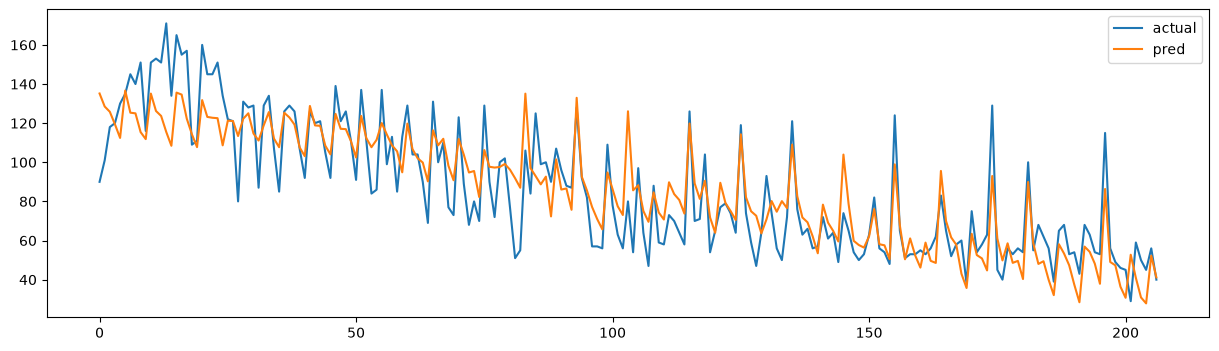

In [33]:
# y_trainと予測値のRMSEを出す
from sklearn.metrics import mean_squared_error as MSE
print("RMSE",np.sqrt(MSE(y_train,Linear_pred)))

# 線形回帰の予測値と実数値のグラフ
p = pd.DataFrame({"actual":y_train,"pred":Linear_pred})
p.plot(figsize=(15,4))

In [34]:
# RandomForestのパラメータ設定
from sklearn.ensemble import RandomForestRegressor


randomforest = RandomForestRegressor(n_estimators=100,max_depth=4,random_state=2018)

# 残差 = 実測値 - 予測値 を求める
pred_sub = y_train - Linear_pred

# RandomForestの説明変数には全てのカラムを使う
randomforest_X_train = train.drop(['y'],axis=1)

# randomforest_X_trainを説明変数、pred_sub（残差）を目的変数にし、モデル作成
randomforest_X_train = train.drop(['y', 'datetime'], axis=1)

# 残差を予測するRandomForestモデルを学習
randomforest.fit(randomforest_X_train, pred_sub)

RandomForestRegressor(max_depth=4, random_state=2018)

In [35]:
# 線形回帰の予測値に、RandomForestで予測した残差を足し合わせたものを、最終的な予測値とする
combined_pred = linear.predict(linear_X_train) + randomforest.predict(randomforest_X_train)

In [36]:
print(combined_pred)
#最終予測値を出力する

[103.6577676  109.0890503  118.74563283 120.22519608 120.66370606
 144.97562806 140.05535558 143.11218811 138.96649807 127.90342143
 152.80937695 146.06546961 146.82267026 143.08305394 128.99657633
 158.94403695 157.5021457  145.30073017 133.57874046 122.14977246
 151.20312586 144.07143166 143.85825911 146.28410092 127.60834206
 125.98528589 120.98749213 112.68904199 121.58642193 124.97136744
 114.35559523 106.50585752 118.71329185 123.43784859 108.15275562
 102.24042126 126.67076201 119.53408749 115.79643366 104.10696303
  98.14796473 128.37992347 115.24001706 115.32916713 104.15970419
  98.57164441 124.6683748  112.88674114 113.16755926 106.15564837
  96.66366615 122.95727745 108.40600562 102.07970777 104.86818925
 119.36894092 109.30951715 105.05728989 101.05272537  90.17229998
 119.09837788 103.25936598 100.27929643  94.3157939   83.10979143
 115.684567   104.20139902 107.19961389  93.11059696  85.39649622
 113.02285384  99.97935104  91.73654909  92.7375964   78.75287723
 107.42506

In [ ]:
sample[1] = combined_pred
sample.head()
#sampleファイルを上書きする

ValueError: Length of values (207) does not match length of index (40)

In [ ]:
# 学習用データ
# 説明変数に "temperature (温度)" を利用
X_train = train['temperature']
# 目的変数に "y (売り上げ個数)" を利用
y_train = train['y']

# 検証用（予測用）データ
X_test  = test['temperature']

In [ ]:
X_train.head()

X_train.shape
# > (207,)

(207,)

In [ ]:
X_train = X_train.values.reshape(-1,1)
X_test = X_test.values.reshape(-1,1)
#トレーニングデータとテストデータを一列データにする

In [ ]:
print(X_train)
#X_trainを表示

[[19.8]
 [17. ]
 [15.5]
 [15.2]
 [16.1]
 [14.6]
 [17.9]
 [14.7]
 [17.7]
 [12.1]
 [13.8]
 [13.9]
 [13.5]
 [13.8]
 [14.9]
 [ 9.1]
 [ 7.1]
 [11. ]
 [12.3]
 [13.9]
 [11.3]
 [10.8]
 [ 7.8]
 [ 6.8]
 [ 8.4]
 [11.5]
 [ 8. ]
 [ 7.3]
 [ 7.3]
 [ 9.8]
 [10.9]
 [ 5.1]
 [ 5.8]
 [ 2.9]
 [ 7. ]
 [ 7.8]
 [ 6.5]
 [10.4]
 [ 7.4]
 [ 8.5]
 [10.1]
 [ 5.1]
 [12.6]
 [10.3]
 [15.3]
 [14.1]
 [15.9]
 [ 3.8]
 [ 3. ]
 [ 4.2]
 [ 5.5]
 [ 7.8]
 [ 6.3]
 [ 6.4]
 [ 1.2]
 [11.6]
 [ 6.8]
 [ 7.3]
 [ 5.4]
 [ 8.5]
 [ 6.6]
 [10.5]
 [11.5]
 [ 8.5]
 [17.7]
 [ 7.8]
 [ 8.3]
 [ 6.1]
 [ 6.7]
 [ 7. ]
 [ 7.6]
 [ 8.7]
 [14.8]
 [15.2]
 [11.5]
 [14. ]
 [18.9]
 [12.6]
 [ 7.5]
 [17.4]
 [18.9]
 [18.7]
 [12.4]
 [18.5]
 [17.5]
 [16.1]
 [18.2]
 [14.3]
 [17.8]
 [13.8]
 [20.1]
 [19. ]
 [21.3]
 [16.5]
 [16.4]
 [19.7]
 [21.5]
 [20.1]
 [11.4]
 [16.4]
 [18.8]
 [19.4]
 [19.9]
 [20.8]
 [22.7]
 [17.5]
 [24. ]
 [23.3]
 [18.9]
 [21. ]
 [23.4]
 [22.7]
 [18.6]
 [26. ]
 [19.3]
 [23.8]
 [22.8]
 [23.9]
 [17.4]
 [19. ]
 [19.8]
 [23.9]
 [23.7]
 [25.7]
 [26. ]


In [ ]:
#X_testを表示
print(X_test)

[[20.2]
 [23.9]
 [28.7]
 [21.5]
 [22.1]
 [23.3]
 [22.5]
 [26.1]
 [26.8]
 [15.6]
 [18.6]
 [23. ]
 [23.9]
 [20.2]
 [15.5]
 [14.7]
 [18.7]
 [22.7]
 [19.1]
 [19.6]
 [19.6]
 [18.8]
 [18.9]
 [16. ]
 [19.2]
 [20.1]
 [21.2]
 [14.7]
 [14.4]
 [19.5]
 [15.8]
 [14.3]
 [16.1]
 [14.9]
 [10.5]
 [14.9]
 [11.4]
 [ 9.2]
 [15.1]
 [15.3]]


In [ ]:
X_train.shape
#行数と列数を確認

(207, 1)

In [ ]:
model = LR()
#モデルを代入

In [ ]:
model.fit(X_train, y_train)
#データを学習させる

LinearRegression()

In [ ]:
model.coef_ #傾き
# > array([-2.5023821])

model.intercept_ #切片
# > 134.79948383749922

np.float64(134.79948383749922)

In [ ]:
# 検証（決定係数の計算）
model.score(X_train, y_train)

# > 0.4294602815194137

0.42946028151941373

In [ ]:
Linear_pred2 = model.predict(X_test)
print(Linear_pred2)
#予測実行

[ 84.25136537  74.99255159  62.9811175   80.99826864  79.49683938
  76.49398085  78.49588653  69.48731097  67.73564349  95.76232304
  88.25517673  77.24469548  74.99255159  84.25136537  96.01256125
  98.01446693  88.00493852  77.99541011  87.00398568  85.75279463
  85.75279463  87.75470031  87.5044621   94.7613702   86.75374747
  84.50160358  81.74898327  98.01446693  98.76518156  86.00303284
  95.26184662  99.01541977  94.51113199  97.51399051 108.52447176
  97.51399051 106.27232787 111.7775685   97.01351409  96.51303767]


In [ ]:
sample.head()
#サンプルを確認

,0,1
0,2014-10-1,24
1,2014-10-2,71
2,2014-10-3,25
3,2014-10-6,32
4,2014-10-7,60


In [ ]:
sample[1] = Linear＿pred2
sample.head()
#sampleファイルを上書きする

,0,1
0,2014-10-1,84.251365
1,2014-10-2,74.992552
2,2014-10-3,62.981117
3,2014-10-6,80.998269
4,2014-10-7,79.496839


In [ ]:
sample.to_csv('submit1.csv', index=None, header=None)
#sampleファイルをcsv化する